In [1]:
'''
S. Arman Ghaffarizadeh & Gerald J. Wang
Getting over the Hump with KAMEL-LOBE: Kernel-Averaging Method to Eliminate Length-Of-Bin Effects in Radial Distribution Functions
Journal of Chemical Physics (2023)
'''

import numpy as np
from scipy.stats import norm
import scipy.sparse as sp
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema

''' 
python version of KAMEL_LOBE
Nick Hattrup
December 2, 2024
'''


def compute_T1(delr, Nbins):
    """
    Args:
        delr (float): bin width
        Nbins (int): number of bins

    Returns:
        T1 (array): T1 matrix of size Nbins x Nbins
    """
    T1 = np.zeros((Nbins,Nbins)) 
    for col in range(1, Nbins): # First column is all zeros
        value = (col*delr)**2
        T1[col, col] = value
        T1[col+1:, col] = 2*value
    return T1

def compute_T2(delr, Nbins, w):
    """
    Args:
        delr (float): bin width
        Nbins (int): number of bins

    Returns:
        T2 (array): T2 matrix of size Nbins x Nbins
    """
    m_KL = np.ceil(2*w/delr).astype(int) # number of bins to average over
    k_KL = 2*m_KL-1
    fractions = np.zeros((1,k_KL))
    A1_block = sp.identity(m_KL, format='csr')
    A2_block = sp.lil_matrix((m_KL, Nbins-m_KL))
    fractions[0,m_KL-1:] = norm.cdf(((np.arange(0,m_KL)+0.5)*delr),0,w)-norm.cdf(((np.arange(0,m_KL)-0.5)*delr),0,w)        
    fractions[0,:m_KL-1] = np.flip(fractions[0,m_KL:2*m_KL-1])
    fractions[0, :] *= 1/np.sum(fractions)
    B_block = sp.diags(np.tile(fractions, (Nbins-2*m_KL, 1)).T, np.arange(0, 2*(m_KL-1)+1), shape=(Nbins-2*m_KL, Nbins))
    T2 = sp.vstack((sp.hstack((A1_block, A2_block)), B_block, sp.hstack((A2_block, A1_block))))
    return T2

def compute_T3(delr, Nbins):
    """
    Args:
        delr (float): bin width
        Nbins (int): number of bins
        density (float): density of the system

    Returns:
        T3 (array): T3 matrix of size Nbins x Nbins
    """
    T3 = np.zeros((Nbins,Nbins))
    constant = 1/(delr**2)
    for row in range(1, Nbins):
        T3[row, row] = constant/(row)**2
        factor = 2*constant/(row)**2
        sign = 1 - 2 * (row & 1)
        for col in range(row):
            T3[row, col] = sign*factor
            sign *= -1
    # T3 /= 2.*np.pi*density*delr
    return T3


def KAMEL_LOBE(r,RDF,w=0.015):
    """
    Args:
        r (array): vector of equispaced radii at which RDF is evaluated
        RDF (array): vector of corresponding RDF values
        varargin (float, optional): width of Gaussian kernel (set to 0.015 by default)

    Returns:
        r_tilde (array): vector of equispaced radii at which KAMEL-LOBE RDF is evaluated
        gr_tilde (array): vector of corresponding KAMEL-LOBE RDF values
    """
    Nbins = RDF.shape[0] # number of bins
    delr = r[1]-r[0] # bin width, MATLAB version uses r[2]-r[1]
    print(2*w/delr)
    m_KL = np.ceil(2*w/delr).astype(int) # number of bins to average over
    print(m_KL)

    if m_KL > 1:
        T1 = compute_T1(delr, Nbins)
        T2 = compute_T2(delr, Nbins, w)
        T3 = compute_T3(delr, Nbins)

        # Computing gr_tilde
        gr_convert = T3@(T2@(T1@RDF)) # Explicit operation order to reduce redundant matrix multiplications
        gr_tilde = gr_convert[:-m_KL]    
        r_tilde = r[:-m_KL]
        return r_tilde, gr_tilde
    
    else:
        gr_tilde = RDF
        r_tilde = r
        print('w <= delr/2, no averaging is performed')
        return r_tilde, gr_tilde


In [2]:
# Load the data: handles semicolon delimiter and spaces after semicolons
file = "rdf_C4Cl2H8_C4Cl2H8_[#1r_#1o].csv"

df = pd.read_csv(file, sep=';', skipinitialspace=True)

# Clean column names by removing the '#' and stripping whitespace
df.columns = [c.replace('#', '').strip() for c in df.columns]

In [3]:
import numpy as np
from scipy.integrate import cumulative_trapezoid

# Parameters
rho = 256/(3998.5042)**3  # Example density
r_limit = 10000 # The r' value you want to integrate up to

# Map columns based on the file structure
x_col = df.columns[0]  # Distance / pm
gr_col = 'g(r)'
int_col = 'Integral'
# Example data (Replace these with your actual arrays)
r = np.array(df[x_col])
g = np.array(df[gr_col]) # Replace with your actual g(r) array

r, g = KAMEL_LOBE(r, g, w=10)

full_integrand = g * (r**2)

# Compute cumulative integral
# initial=0 ensures the output array is the same length as r
cumulative_int = cumulative_trapezoid(full_integrand, x=r, initial=0)

# Multiply by constants
n_profile = 4 * np.pi * rho * cumulative_int

6.000000000600001
7


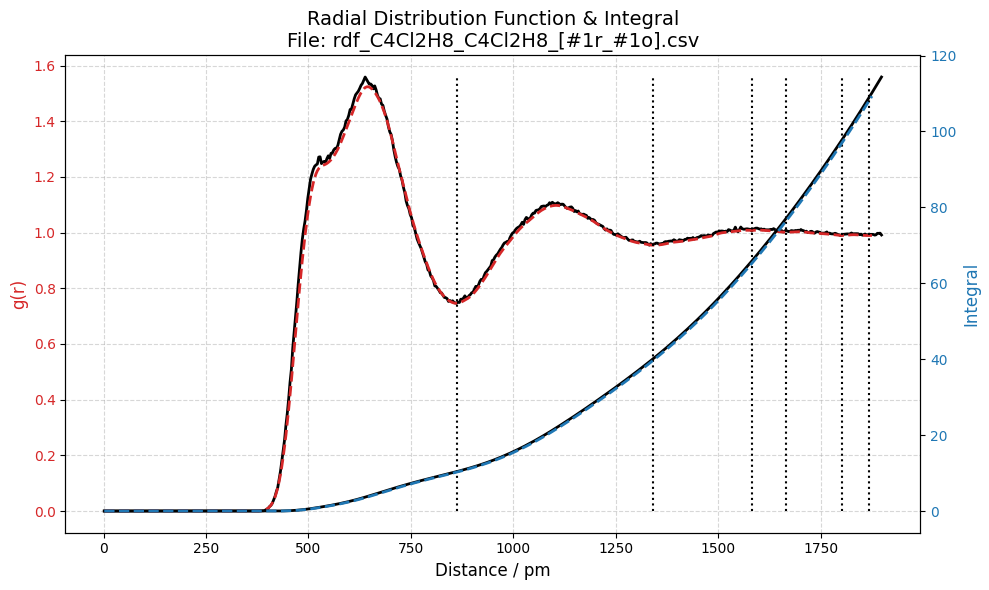

In [4]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# --- Plot g(r) on the LEFT Y-axis ---
color_gr = 'tab:red'
ax1.set_xlabel(x_col, fontsize=12)
ax1.set_ylabel(gr_col, color=color_gr, fontsize=12)
ax1.plot(df[x_col],df[gr_col], color='black', label='og g(r)', linewidth=2)
ax1.plot(r,g, color=color_gr, label=gr_col, linewidth=2, linestyle='--')
ax1.tick_params(axis='y', labelcolor=color_gr)
ax1.grid(True, linestyle='--', alpha=0.5)

y_max = df[gr_col].max()

# Find all local maxima (peaks)
# peaks = argrelextrema(np.array(df[gr_col]), np.less)
# ax1.vlines(x=np.array(df[x_col])[peaks], ymin=0, ymax=y_max, color='black', linestyle=':')
peaks = argrelextrema(g, np.less)
ax1.vlines(x=r[peaks], ymin=0, ymax=y_max, color='black', linestyle=':')

# --- Plot Integral on the RIGHT Y-axis ---
ax2 = ax1.twinx() 
color_int = 'tab:blue'
ax2.set_ylabel(int_col, color=color_int, fontsize=12)
ax2.plot(df[x_col], df[int_col], color='black', linewidth=2)
ax2.plot(r, n_profile, color=color_int, label=int_col, linewidth=2, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color_int)

plt.title(f"Radial Distribution Function & Integral\nFile: {file}", fontsize=14)
fig.tight_layout()

In [5]:
n_profile[peaks]

array([ 10.24370904,  39.73496956,  65.19512537,  76.31523782,
        96.94073843, 108.13434724])

In [6]:
# Load the data: handles semicolon delimiter and spaces after semicolons
file = "rdf_C4Cl2H8_C5H12O_[#1r_#1o].csv"

df = pd.read_csv(file, sep=';', skipinitialspace=True)

# Clean column names by removing the '#' and stripping whitespace
df.columns = [c.replace('#', '').strip() for c in df.columns]

In [7]:
import numpy as np
from scipy.integrate import cumulative_trapezoid

# Parameters
rho = 87/(3998.5042)**3  # Example density
r_limit = 10000 # The r' value you want to integrate up to

# Map columns based on the file structure
x_col = df.columns[0]  # Distance / pm
gr_col = 'g(r)'
int_col = 'Integral'
# Example data (Replace these with your actual arrays)
r = np.array(df[x_col])
g = np.array(df[gr_col]) # Replace with your actual g(r) array

r, g = KAMEL_LOBE(r, g, w=10)

full_integrand = g * (r**2)

# Compute cumulative integral
# initial=0 ensures the output array is the same length as r
cumulative_int = cumulative_trapezoid(full_integrand, x=r, initial=0)

# Multiply by constants
n_profile = 4 * np.pi * rho * cumulative_int

6.000000000600001
7


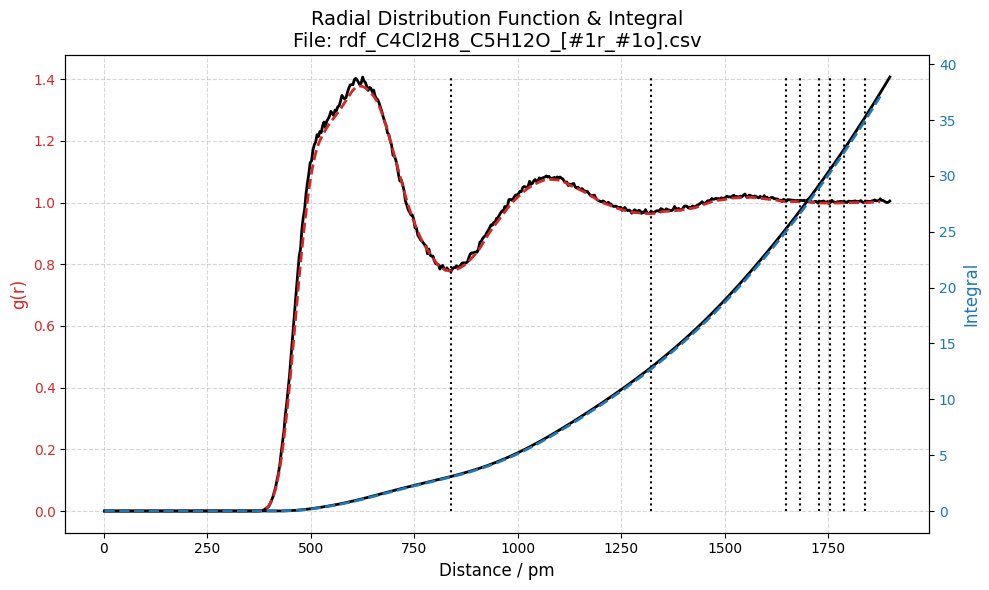

In [8]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# --- Plot g(r) on the LEFT Y-axis ---
color_gr = 'tab:red'
ax1.set_xlabel(x_col, fontsize=12)
ax1.set_ylabel(gr_col, color=color_gr, fontsize=12)
ax1.plot(df[x_col],df[gr_col], color='black', label='og g(r)', linewidth=2)
ax1.plot(r,g, color=color_gr, label=gr_col, linewidth=2, linestyle='--')
ax1.tick_params(axis='y', labelcolor=color_gr)
ax1.grid(True, linestyle='--', alpha=0.5)

y_max = df[gr_col].max()

# Find all local maxima (peaks)
# peaks = argrelextrema(np.array(df[gr_col]), np.less)
# ax1.vlines(x=np.array(df[x_col])[peaks], ymin=0, ymax=y_max, color='black', linestyle=':')
peaks = argrelextrema(g, np.less)
ax1.vlines(x=r[peaks], ymin=0, ymax=y_max, color='black', linestyle=':')

# --- Plot Integral on the RIGHT Y-axis ---
ax2 = ax1.twinx() 
color_int = 'tab:blue'
ax2.set_ylabel(int_col, color=color_int, fontsize=12)
ax2.plot(df[x_col], df[int_col], color='black', linewidth=2)
ax2.plot(r, n_profile, color=color_int, label=int_col, linewidth=2, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color_int)

plt.title(f"Radial Distribution Function & Integral\nFile: {file}", fontsize=14)
fig.tight_layout()

In [9]:
n_profile[peaks]

array([ 3.04574047, 12.71754348, 25.07499342, 26.66099791, 28.9845192 ,
       30.36598293, 32.15300399, 34.96399999])

In [10]:
# Load the data: handles semicolon delimiter and spaces after semicolons
file = "rdf_C5H12O_C4Cl2H8_[#1r_#1o].csv"

df = pd.read_csv(file, sep=';', skipinitialspace=True)

# Clean column names by removing the '#' and stripping whitespace
df.columns = [c.replace('#', '').strip() for c in df.columns]

In [11]:
import numpy as np
from scipy.integrate import cumulative_trapezoid

# Parameters
rho = 256/(3998.5042)**3  # Example density
r_limit = 10000 # The r' value you want to integrate up to

# Map columns based on the file structure
x_col = df.columns[0]  # Distance / pm
gr_col = 'g(r)'
int_col = 'Integral'
# Example data (Replace these with your actual arrays)
r = np.array(df[x_col])
g = np.array(df[gr_col]) # Replace with your actual g(r) array

r, g = KAMEL_LOBE(r, g, w=10)

full_integrand = g * (r**2)

# Compute cumulative integral
# initial=0 ensures the output array is the same length as r
cumulative_int = cumulative_trapezoid(full_integrand, x=r, initial=0)

# Multiply by constants
n_profile = 4 * np.pi * rho * cumulative_int

6.000000000600001
7


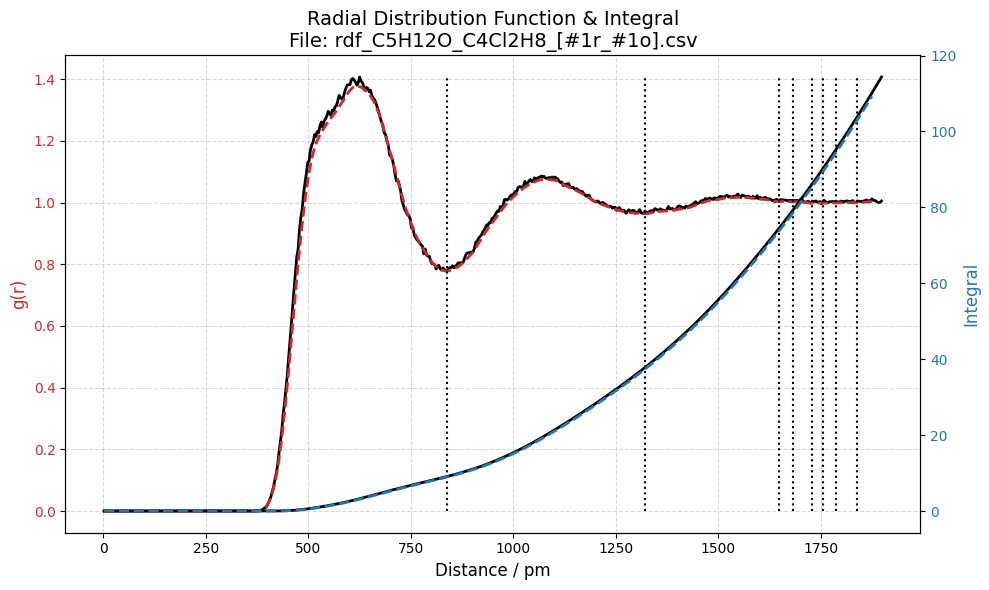

In [12]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# --- Plot g(r) on the LEFT Y-axis ---
color_gr = 'tab:red'
ax1.set_xlabel(x_col, fontsize=12)
ax1.set_ylabel(gr_col, color=color_gr, fontsize=12)
ax1.plot(df[x_col],df[gr_col], color='black', label='og g(r)', linewidth=2)
ax1.plot(r,g, color=color_gr, label=gr_col, linewidth=2, linestyle='--')
ax1.tick_params(axis='y', labelcolor=color_gr)
ax1.grid(True, linestyle='--', alpha=0.5)

y_max = df[gr_col].max()

# Find all local maxima (peaks)
# peaks = argrelextrema(np.array(df[gr_col]), np.less)
# ax1.vlines(x=np.array(df[x_col])[peaks], ymin=0, ymax=y_max, color='black', linestyle=':')
peaks = argrelextrema(g, np.less)
ax1.vlines(x=r[peaks], ymin=0, ymax=y_max, color='black', linestyle=':')

# --- Plot Integral on the RIGHT Y-axis ---
ax2 = ax1.twinx() 
color_int = 'tab:blue'
ax2.set_ylabel(int_col, color=color_int, fontsize=12)
ax2.plot(df[x_col], df[int_col], color='black', linewidth=2)
ax2.plot(r, n_profile, color=color_int, label=int_col, linewidth=2, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color_int)

plt.title(f"Radial Distribution Function & Integral\nFile: {file}", fontsize=14)
fig.tight_layout()

In [13]:
n_profile[peaks]

array([  8.96217887,  37.42173714,  73.78388868,  78.45075247,
        85.28778064,  89.35277737,  94.61113817, 102.88257469])

In [14]:
# Load the data: handles semicolon delimiter and spaces after semicolons
file = "rdf_C5H12O_C5H12O_[#1r_#1o].csv"

df = pd.read_csv(file, sep=';', skipinitialspace=True)

# Clean column names by removing the '#' and stripping whitespace
df.columns = [c.replace('#', '').strip() for c in df.columns]

In [15]:
import numpy as np
from scipy.integrate import cumulative_trapezoid

# Parameters
rho = 87/(3998.5042)**3  # Example density
r_limit = 10000 # The r' value you want to integrate up to

# Map columns based on the file structure
x_col = df.columns[0]  # Distance / pm
gr_col = 'g(r)'
int_col = 'Integral'
# Example data (Replace these with your actual arrays)
r = np.array(df[x_col])
g = np.array(df[gr_col]) # Replace with your actual g(r) array

r, g = KAMEL_LOBE(r, g, w=10)

full_integrand = g * (r**2)

# Compute cumulative integral
# initial=0 ensures the output array is the same length as r
cumulative_int = cumulative_trapezoid(full_integrand, x=r, initial=0)

# Multiply by constants
n_profile = 4 * np.pi * rho * cumulative_int

6.000000000600001
7


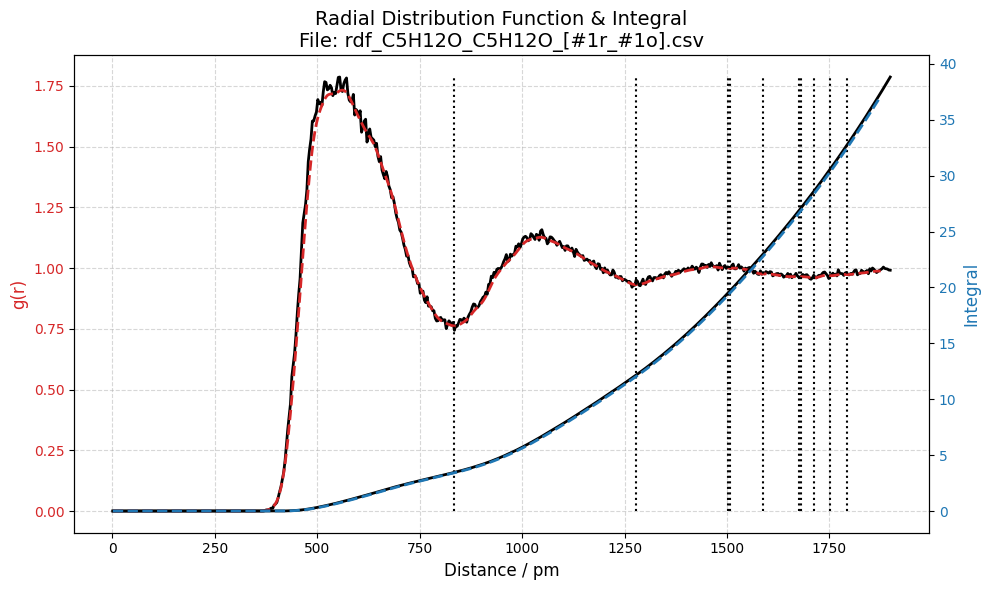

In [16]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# --- Plot g(r) on the LEFT Y-axis ---
color_gr = 'tab:red'
ax1.set_xlabel(x_col, fontsize=12)
ax1.set_ylabel(gr_col, color=color_gr, fontsize=12)
ax1.plot(df[x_col],df[gr_col], color='black', label='og g(r)', linewidth=2)
ax1.plot(r,g, color=color_gr, label=gr_col, linewidth=2, linestyle='--')
ax1.tick_params(axis='y', labelcolor=color_gr)
ax1.grid(True, linestyle='--', alpha=0.5)

y_max = df[gr_col].max()

# Find all local maxima (peaks)
# peaks = argrelextrema(np.array(df[gr_col]), np.less)
# ax1.vlines(x=np.array(df[x_col])[peaks], ymin=0, ymax=y_max, color='black', linestyle=':')
peaks = argrelextrema(g, np.less)
ax1.vlines(x=r[peaks], ymin=0, ymax=y_max, color='black', linestyle=':')

# --- Plot Integral on the RIGHT Y-axis ---
ax2 = ax1.twinx() 
color_int = 'tab:blue'
ax2.set_ylabel(int_col, color=color_int, fontsize=12)
ax2.plot(df[x_col], df[int_col], color='black', linewidth=2)
ax2.plot(r, n_profile, color=color_int, label=int_col, linewidth=2, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color_int)

plt.title(f"Radial Distribution Function & Integral\nFile: {file}", fontsize=14)
fig.tight_layout()

In [17]:
n_profile[peaks]

array([ 3.41295954, 12.0344184 , 19.28086222, 19.53902656, 22.788701  ,
       26.61475254, 26.924407  , 28.34569899, 30.32736866, 32.41409972])

Successfully plotted: rdf_C5H12O_C5H12O_[#1r_#1o]_plot.png


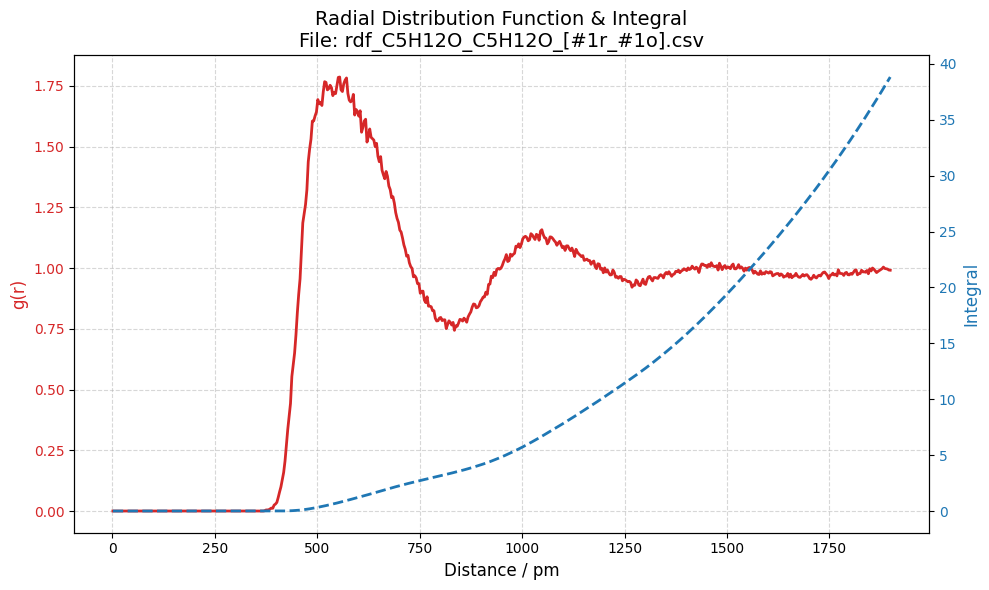

Successfully plotted: rdf_C5H12O_C4Cl2H8_[#1r_#1o]_long_plot.png


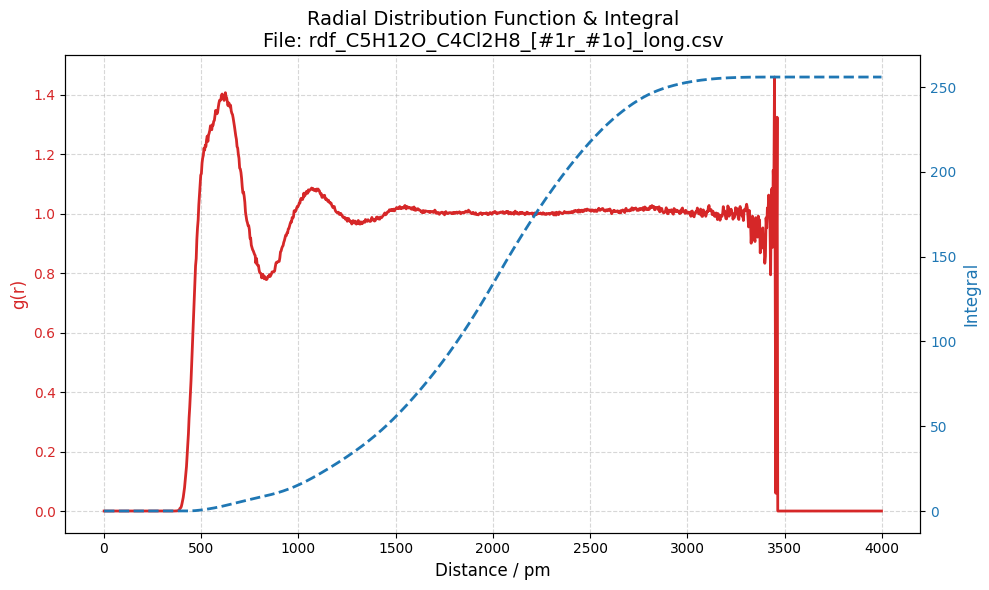

Successfully plotted: rdf_C4Cl2H8_C4Cl2H8_[#1r_#1o]_plot.png


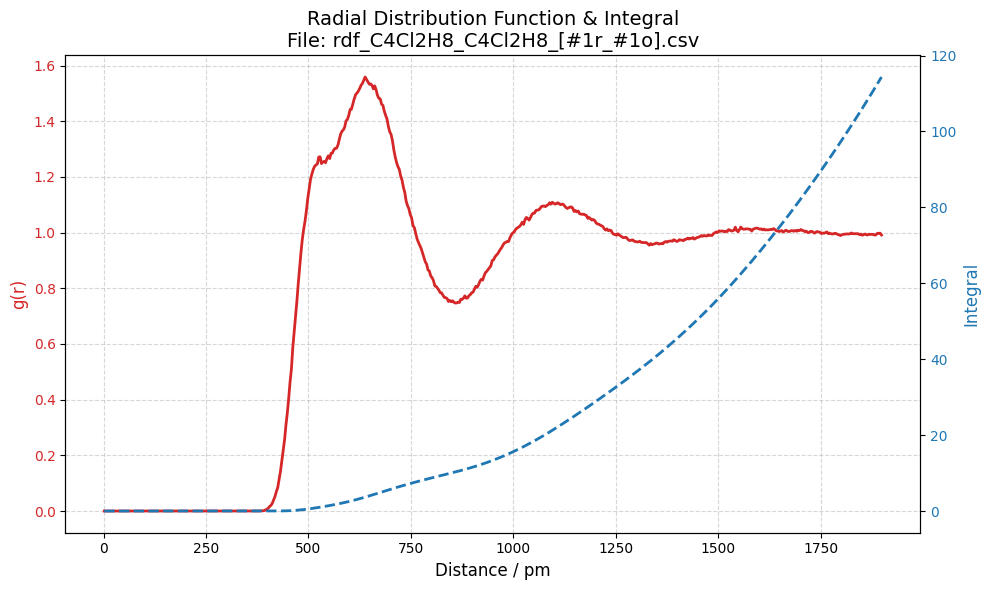

Successfully plotted: rdf_C5H12O_C4Cl2H8_[#1r_#1o]_plot.png


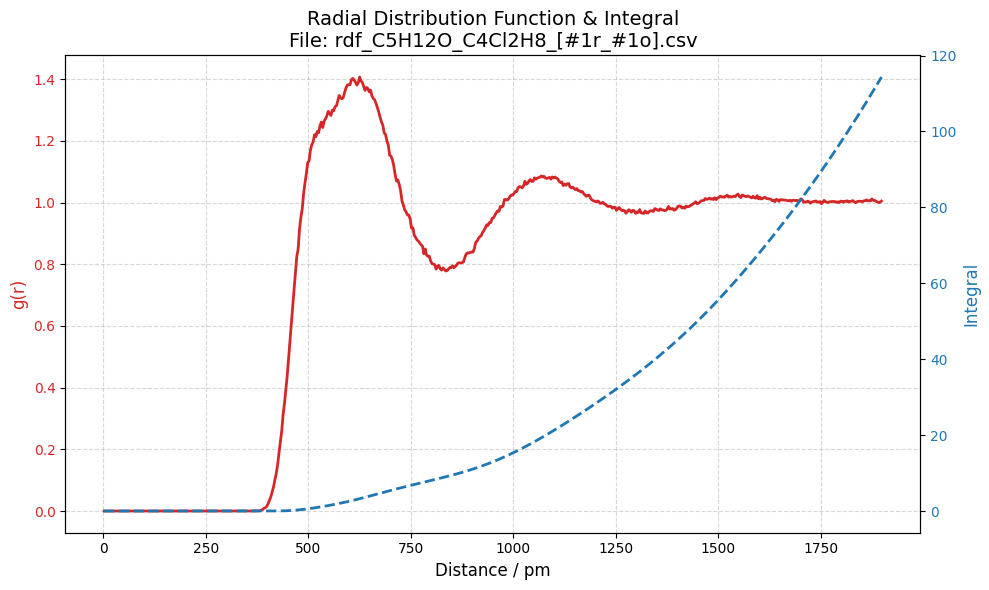

Successfully plotted: rdf_C4Cl2H8_C4Cl2H8_[#1r_#1o]_long_plot.png


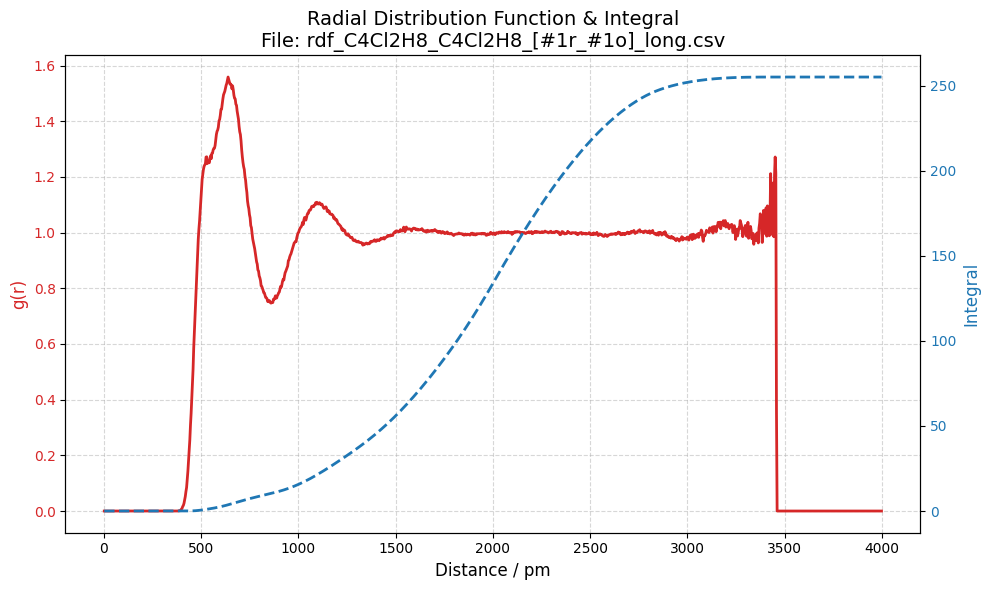

Successfully plotted: rdf_C5H12O_C5H12O_[#1r_#1o]_long_plot.png


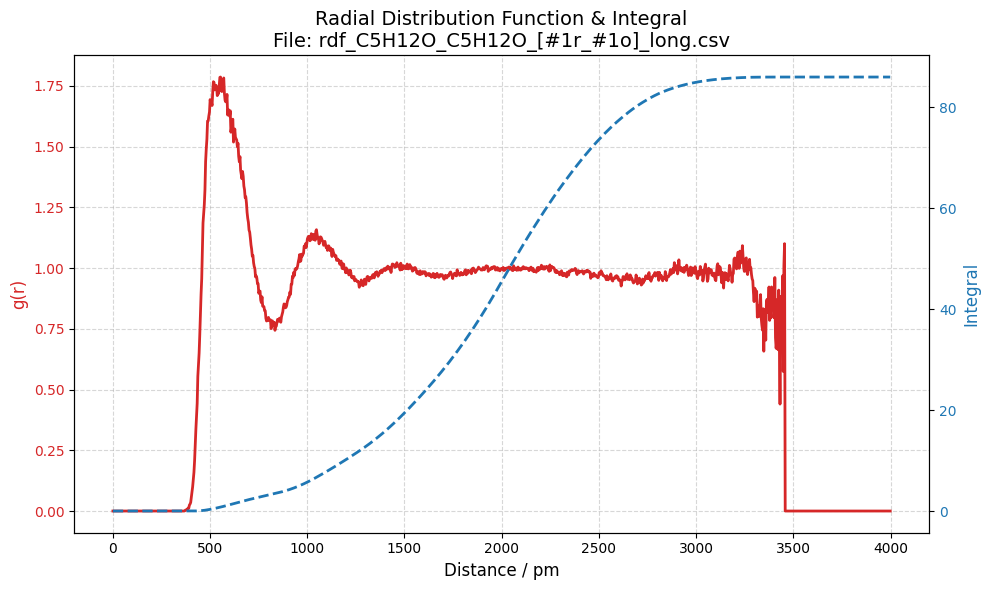

Successfully plotted: rdf_C4Cl2H8_C5H12O_[#1r_#1o]_plot.png


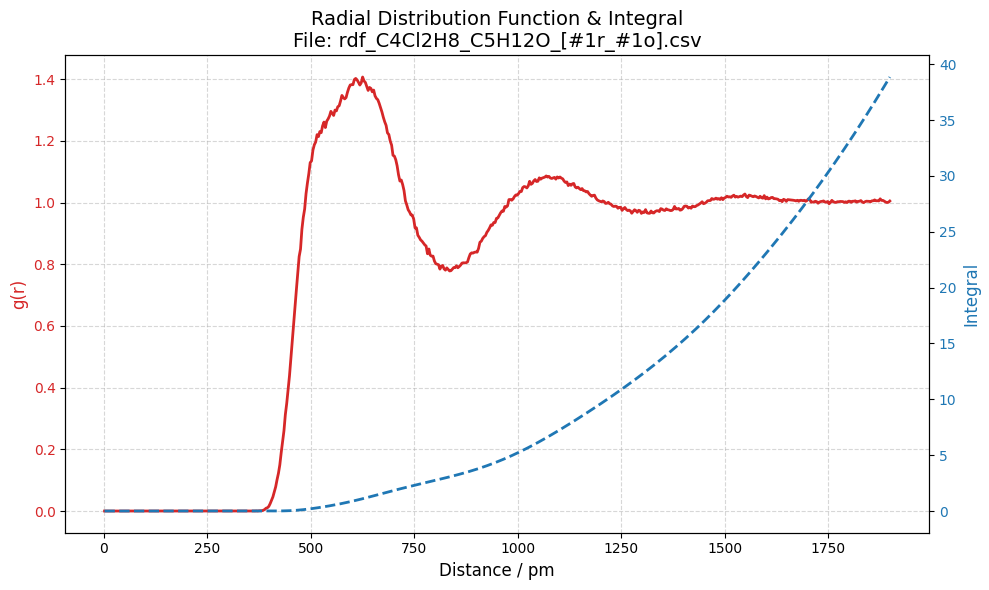

Successfully plotted: rdf_C4Cl2H8_C5H12O_[#1r_#1o]_long_plot.png


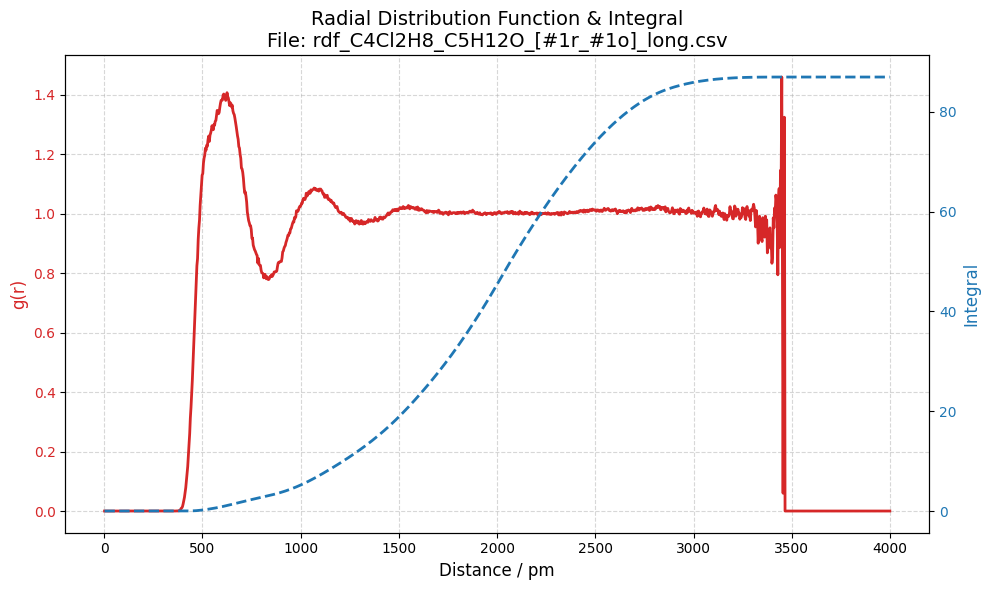

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
import numpy as np

# Find all CSV files in the directory
csv_files = glob.glob("*.csv")

for file in csv_files:
    try:
        # Load the data: handles semicolon delimiter and spaces after semicolons
        df = pd.read_csv(file, sep=';', skipinitialspace=True)
        
        # Clean column names by removing the '#' and stripping whitespace
        df.columns = [c.replace('#', '').strip() for c in df.columns]
        
        # Map columns based on the file structure
        x_col = df.columns[0]  # Distance / pm
        gr_col = 'g(r)'
        int_col = 'Integral'

        fig, ax1 = plt.subplots(figsize=(10, 6))

        # --- Plot g(r) on the LEFT Y-axis ---
        color_gr = 'tab:red'
        ax1.set_xlabel(x_col, fontsize=12)
        ax1.set_ylabel(gr_col, color=color_gr, fontsize=12)
        ax1.plot(df[x_col], df[gr_col], color=color_gr, label=gr_col, linewidth=2)
        ax1.tick_params(axis='y', labelcolor=color_gr)
        ax1.grid(True, linestyle='--', alpha=0.5)

        # --- Plot Integral on the RIGHT Y-axis ---
        ax2 = ax1.twinx() 
        color_int = 'tab:blue'
        ax2.set_ylabel(int_col, color=color_int, fontsize=12)
        ax2.plot(df[x_col], df[int_col], color=color_int, label=int_col, linewidth=2, linestyle='--')
        ax2.tick_params(axis='y', labelcolor=color_int)

        plt.title(f"Radial Distribution Function & Integral\nFile: {file}", fontsize=14)
        fig.tight_layout()
        
        # Save the plot as a PNG
        output_name = file.replace('.csv', '_plot.png')
        plt.savefig(output_name, dpi=300)
        print(f"Successfully plotted: {output_name}")
        plt.show()

    except Exception as e:
        print(f"Error processing {file}: {e}")